## Initialization

#### Import Library, find available devices

In [1]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict
rm = pyvisa.ResourceManager()    # Create a ResourceManager object, which manages communication with instruments
rm.list_resources()              # List all available resources (e.g., connected instruments) managed by pyvisa
import random


In [2]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


#### Connect Source Meter

In [3]:
#Establishing Connection for SMU
SM = rm.open_resource('GPIB0::21::INSTR')  # Open a connection to the instrument with the address 'ASRL3::INSTR' and assign it to SM
SM.read_termination = '\n'             # Set the read termination character to a newline. This tells pyvisa when to consider a message as complete when reading from the instrument.
SM.write_termination = '\n'            # Set the write termination character to a newline. This ensures that each command sent to the instrument is properly terminated.
SM.baud_rate = 9600                    # Set the baud rate for serial communication to 9600. This is the speed at which data is transmitted over the serial connection.
print(SM)                              # Print the resource object (SM) to display its properties
print(SM.query('*IDN?'))               # Send the '*IDN?' command to the instrument and print its response. This command usually asks the instrument to identify itself (e.g., manufacturer, model number).

GPIBInstrument at GPIB0::21::INSTR
KEITHLEY INSTRUMENTS INC.,MODEL 2401,4636504,B02 Jan 20 2021 10:19:49/B01  /W/N


#### Initialize Source Meter

In [4]:
SM.write("OUTP:STAT 0")                 # Turn off the VIN source meter
SM.write(":SOUR:FUNC:MODE CURR")
SM.write("SENS:FUNC 'VOLT'")
print(SM.query(":CONF?"))               # Query and print the current configuration of the SMU
SM.write("SOUR:CURR:RANG 1")
SM.write("SENS:VOLT:PROT:LEV 2")   # Set the current protection level (compliance) to 10.5 mA. This limits the maximum current to protect the device under test.
SM.write("SENS:VOLT:RANG 2")         # Set the current measurement range to 10 mA. This sets the expected maximum current for accurate measurement.
SM.write("VOLT:NPLC 1")                # Set the number of power line cycles (NPLC) for the current measurement to 10. 
                                            # This controls the integration time, with higher values leading to more accurate but slower measurements.
SM.write(":SYST:RSEN ON")               #sets measurement to 4-wire                                    

"VOLT:DC"


14

## Data

#### Store/Load Data

In [ ]:
def store_data(df, save_dir, SOC, test_name):
    df.to_csv(os.path.join(save_dir, f'{test_name}__SOC={SOC}.csv'), index=False)

# def load_data(load_dir, SOC, test_name):
#     df = ICASL.read_csv(os.path.join(load_dir, f"{test_name}__SOC={VSET}.csv"))
#     df = ICASL.fix_dataframe(df)
#     return df

## Tests

#### Individual Tests

In [21]:
def measure(state):
    global rest_duration
    BAT_INFO=(SM.query(":READ?"))
    times.append(time.perf_counter() - start_time)
    DOD.append(DOD[-1]+(IBAT[-1]*1000*(times[-1]-times[-2])/3600))
    SOC.append(SOC_Initial+DOD[-1]/Total_Capacity)
    IBAT.append(float(BAT_INFO.split(',')[1]))
    VBAT.append(float(BAT_INFO.split(',')[0]))
    State.append(state)
    
    dt = times[-1] - times[-2]
    if IBAT[-1] == 0:
        rest_duration += dt
    else:
        rest_duration = 0
    # Only run predict/update if dt is valid (prevents errors from duplicate timestamps)
    if dt > 0:
        ekf.predict(-IBAT[-1], dt)
        soc = ekf.update(VBAT[-1], -IBAT[-1], rest_duration)
        estimated_soc.append(soc)
    else:
        estimated_soc.append(estimated_soc[-1]) # Keep last value
    

def update_lines():
    #ax1.plot(times[-1], VBAT[-1],marker='.', color='blue')
    #ax2.plot(times[-1], IBAT[-1],marker='.', color='red')
    lineV.set_data(times, VBAT)
    ax1.relim()
    ax1.autoscale_view()
    lineI.set_data(times, IBAT)
    ax2.relim()
    ax2.autoscale_view()
    lineDOD.set_data(times, DOD)
    ax3.relim()
    ax3.autoscale_view()
    lineEKF.set_data(times, estimated_soc)
    lineCC.set_data(times, SOC)
    ax4.relim()
    ax4.autoscale_view()
    display(fig)
    clear_output(wait = True)

def test_rest():
    test_time_start=times[-1]
    test_time_fast=15
    test_time=60*random.uniform(1, 4)
    test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC .1")
    SM.write("SOUR:CURR:LEV 0")
    while test_time_current<test_time_fast: 
        #time.sleep(.05)
        measure(0)
        #update_lines()
        test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC 1")
    #print(len(times))
    #sys.close()
    while test_time_current<test_time: 
        #time.sleep(1)
        measure(0)
        update_lines()
        test_time_current=times[-1]-test_time_start

def test_charge(current):
    test_time_start=times[-1]
    test_time_fast=15
    test_time=60*random.uniform(1, 5)
    test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC .1")
    SM.write("SOUR:CURR:LEV "+ str(current))
    while test_time_current<test_time_fast: 
        measure(1)
        #update_lines()
        test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC 1")
    while test_time_current<test_time: 
        time.sleep(1)
        measure(2)
        update_lines()
        if VBAT[-1] > 1.54 or VBAT[-1] < .8:
            break
        test_time_current=times[-1]-test_time_start

def test_discharge(current):
    test_time_start=times[-1]
    test_time_fast=15
    test_time=60*random.uniform(3, 10)
    test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC .1")
    SM.write("SOUR:CURR:LEV "+ str(current))
    while test_time_current<test_time_fast: 
        measure(1)
        #update_lines()
        test_time_current=times[-1]-test_time_start
    SM.write("VOLT:NPLC 1")
    while test_time_current<test_time: 
        time.sleep(1)
        measure(2)
        update_lines()
        if VBAT[-1] > 1.54 or VBAT[-1] < .8:
            break
        test_time_current=times[-1]-test_time_start



In [285]:
save_dir = "Charging_3.2"
os.makedirs(save_dir, exist_ok=True)
df = pd.DataFrame({'times': times, 'voltage': VBAT, 'current': IBAT, 'SOC':SOC, 'DOD':DOD, 'state':State})
df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)

#### Full Procedure

KeyboardInterrupt: 

<Figure size 640x480 with 0 Axes>

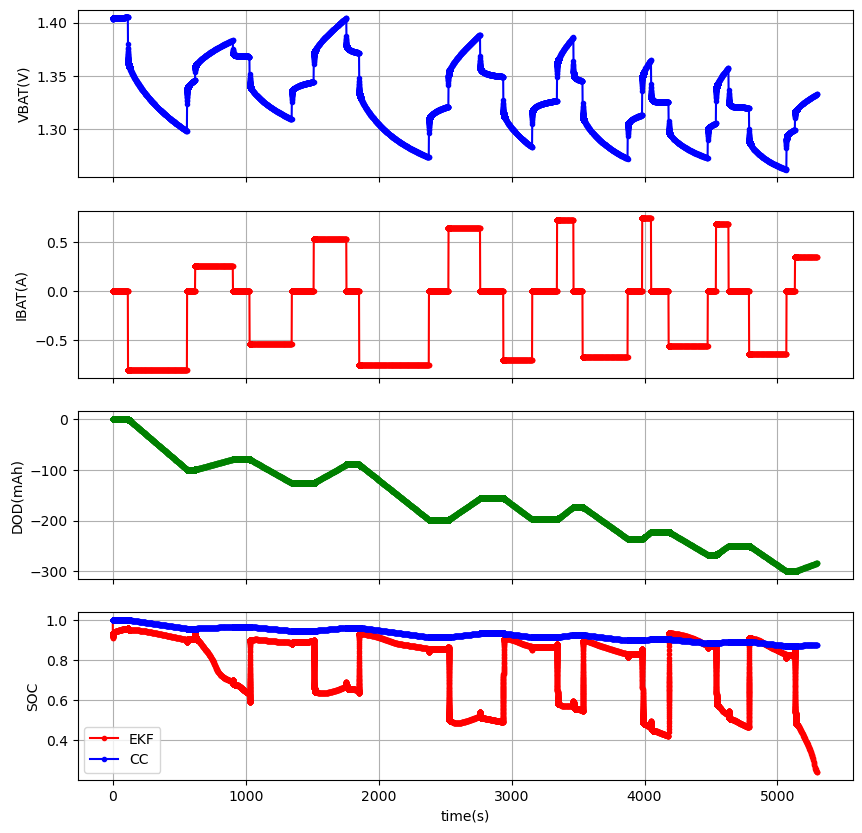

In [22]:
from EKF_Algorithm import BatteryEKF

#df1 = pd.read_csv("Test_1/complete.csv")
#df2 = pd.read_csv("Charging_with_stops/complete.csv")
df2 = pd.read_csv("Charging_combined/complete.csv")
#df1 = pd.read_csv("Discharging_3/complete.csv")
df1 = pd.read_csv("Discharging_2_truncated/complete.csv")

time_offset = df1["times"].iloc[-1]
df2_adjusted = df2.copy()
df2_adjusted["times"] = df2["times"] + time_offset

df = pd.concat([df1, df2_adjusted], ignore_index=True)


df_discharge = pd.read_csv("Discharging_2/BAT_ECM_2.csv")
df_charge = pd.read_csv("Charging_with_stops/BAT_ECM_Charge.csv")


capacity = 2.35
ekf = BatteryEKF(df_charge, df_discharge, capacity)
estimated_soc = []
rest_duration=0



#SM.write("OUTP:STAT 0")
SM.write("VOLT:NPLC 1")
SOC_Initial=1
Total_Capacity=2300
save_dir = "SOC_TEST_2"
os.makedirs(save_dir, exist_ok=True)
current_level = 1
IBAT=[]
VBAT=[]
DOD=[]
times=[]
SOC=[]
State=[]
#Setup Plot
fig = plt.figure()
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax1.grid()
ax2.grid()
ax3.grid()
ax4.grid()
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('DOD(mAh)')
ax4.set_ylabel('SOC')
ax4.set_xlabel('time(s)')
lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(times, VBAT)
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(times, IBAT)
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(times, DOD)
lineEKF, = ax4.plot([], [], '.-', color='red', label="EKF")
lineCC, = ax4.plot([], [], '.-', color='blue', label="CC")
ax4.legend()
lineEKF.set_data(times, estimated_soc)
lineCC.set_data(times, SOC)

SM.write("SOUR:CURR:LEV 0")
SM.write("OUTP:STAT 1")
#initial measurement
BAT_INFO=(SM.query(":READ?"))
start_time = time.perf_counter()
times.append(0)
DOD.append(0)
SOC.append(SOC_Initial)
IBAT.append(float(BAT_INFO.split(',')[1]))
VBAT.append(float(BAT_INFO.split(',')[0]))
State.append(0)
dt = .1
ekf.initialize_soc(VBAT[-1], df_charge["SOC"].values, df_charge["OCV"].values)
estimated_soc.append(SOC_Initial)
update_lines()

while VBAT[-1] > .8 and VBAT[-1] < 1.53:
    #checkpoint=len(times)
    test_rest()
    test_discharge(-1 * random.uniform(.5, 1))
    test_rest()
    test_charge(1 * random.uniform(.25, .75))
    # df = pd.DataFrame({'times': times[checkpoint:], 'voltage': VBAT[checkpoint:], 
    #                    'current': IBAT[checkpoint:], 'SOC':SOC[checkpoint:],
    #                     'DOD':DOD[checkpoint:], 'state':State[checkpoint:]})
    
    # df.to_csv(os.path.join(save_dir, f'SOC={SOC[checkpoint]}.csv'), index=False)

    df = pd.DataFrame({'times': times, 'voltage': VBAT, 'current': IBAT, 'SOC':SOC, 'DOD':DOD, 'state':State})
    df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)
    if times[-1]>16*3600:
        break
checkpoint=len(times)
test_rest()
df = pd.DataFrame({'times': times[checkpoint:], 'voltage': VBAT[checkpoint:], 
                    'current': IBAT[checkpoint:], 'SOC':SOC[checkpoint:],
                    'DOD':DOD[checkpoint:], 'state':State[checkpoint:]})

df.to_csv(os.path.join(save_dir, f'SOC={SOC[checkpoint]}.csv'), index=False)

df = pd.DataFrame({'times': times, 'voltage': VBAT, 'current': IBAT, 'SOC':SOC, 'DOD':DOD, 'state':State})
df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)

SM.write("OUTP:STAT 0")

In [5]:
print("cwd:", os.getcwd())
print("files:", os.listdir())

cwd: c:\Users\lskarda\Desktop\ICASL_test_code\585_SOC_Estimation
files: ['585_DATA_PROCESSING.ipynb', '585_SOC_ESTIMATION.ipynb', 'charged_roll_off', 'Charging', 'Charging_1', 'Charging_2', 'Charging_3', 'Charging_3.1', 'Charging_3.2', 'Charging_3.3', 'Charging_combined', 'Charging_with_stops', 'discharged_roll_off', 'Discharging_2', 'Discharging_2_truncated', 'Discharging_3', 'EKF_Tests', 'Resistor_Test', 'SOC_Algorithm.ipynb', 'Test_1']
